In [1]:
import io
import os
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

# --- Paramètres du projet ---
# La durée de l'appel n'est connue qu'APRÈS l'appel : la garder gonfle les scores
# mais rend le modèle inutilisable pour décider qui appeler. Mets True pour comparer.
USE_DURATION = False

# Coûts métier supposés (à adapter à l'énoncé) :
COUT_FP = 500    # appeler un client qui ne souscrira pas
COUT_FN = 1000   # rater un client qui aurait souscrit

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
LOCAL_CSV = "bank-additional-full.csv"   # si tu l'as déjà téléchargé, place-le à côté du notebook

if os.path.exists(LOCAL_CSV):
    df = pd.read_csv(LOCAL_CSV, sep=";")
else:
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip"
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    z = zipfile.ZipFile(io.BytesIO(r.content))
    df = pd.read_csv(z.open("bank-additional/bank-additional-full.csv"), sep=";")

print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
print("Valeurs manquantes :", int(df.isnull().sum().sum()))
print("\nRépartition de la cible :")
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True).round(3))
df.describe()

Valeurs manquantes : 0

Répartition de la cible :
y
no     36548
yes     4640
Name: count, dtype: int64
y
no     0.887
yes    0.113
Name: proportion, dtype: float64


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [5]:
y = (df["y"] == "yes").astype(int)
X_all = df.drop(columns="y")

NUM_ALL = X_all.select_dtypes(include="number").columns.tolist()
features = [c for c in X_all.columns if USE_DURATION or c != "duration"]
X = X_all[features]

num_cols = [c for c in features if c in NUM_ALL]
cat_cols = [c for c in features if c not in NUM_ALL]
print("Numériques :", num_cols)
print("Catégorielles :", cat_cols)

# Un seul split, stratifié. Le test n'est utilisé qu'à la fin.
X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
X_train, X_test = X_train_all[features], X_test_all[features]
print(f"Train : {len(X_train)} lignes | Test : {len(X_test)} lignes | % positifs train : {y_train.mean():.3f}")

Numériques : ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Catégorielles : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Train : 32950 lignes | Test : 8238 lignes | % positifs train : 0.113


In [6]:
def build_model(feats, class_weight=None):
    nums = [c for c in feats if c in NUM_ALL]
    cats = [c for c in feats if c not in NUM_ALL]
    prep = ColumnTransformer([
        ("num", StandardScaler(), nums),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cats),
    ])
    clf = LogisticRegression(max_iter=3000, class_weight=class_weight, random_state=RANDOM_STATE)
    return Pipeline([("prep", prep), ("clf", clf)])

In [7]:
rows = []
for label, feats in {"sans duration": [c for c in X_all.columns if c != "duration"],
                     "avec duration": list(X_all.columns)}.items():
    m = build_model(feats).fit(X_train_all[feats], y_train)
    p = m.predict_proba(X_test_all[feats])[:, 1]
    rows.append({"Variables": label,
                 "AUC ROC": roc_auc_score(y_test, p),
                 "AUC PR": average_precision_score(y_test, p)})
pd.DataFrame(rows).round(3)

,Variables,AUC ROC,AUC PR
0,sans duration,0.801,0.465
1,avec duration,0.942,0.636


In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_tr = y_train.to_numpy()
grid = np.linspace(0.01, 0.99, 99)


def cost(y_true, y_prob, t):
    y_pred = y_prob >= t
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    return fp * COUT_FP + fn * COUT_FN


candidates = {"standard": None, "balanced": "balanced"}
oof, results = {}, {}
for name, cw in candidates.items():
    oof[name] = cross_val_predict(build_model(features, cw), X_train, y_train,
                                  cv=cv, method="predict_proba")[:, 1]
    costs = np.array([cost(y_tr, oof[name], t) for t in grid])
    results[name] = {"seuil": grid[costs.argmin()], "cout": costs.min(), "couts": costs,
                     "auc": roc_auc_score(y_tr, oof[name])}

pd.DataFrame({k: {"AUC (CV)": v["auc"], "Seuil optimal": v["seuil"], "Coût minimal (train)": v["cout"]}
              for k, v in results.items()}).T.round(3)

,AUC (CV),Seuil optimal,Coût minimal (train)
standard,0.789,0.28,2923500.0
balanced,0.789,0.77,2946000.0


Modèle retenu : standard | seuil = 0.28


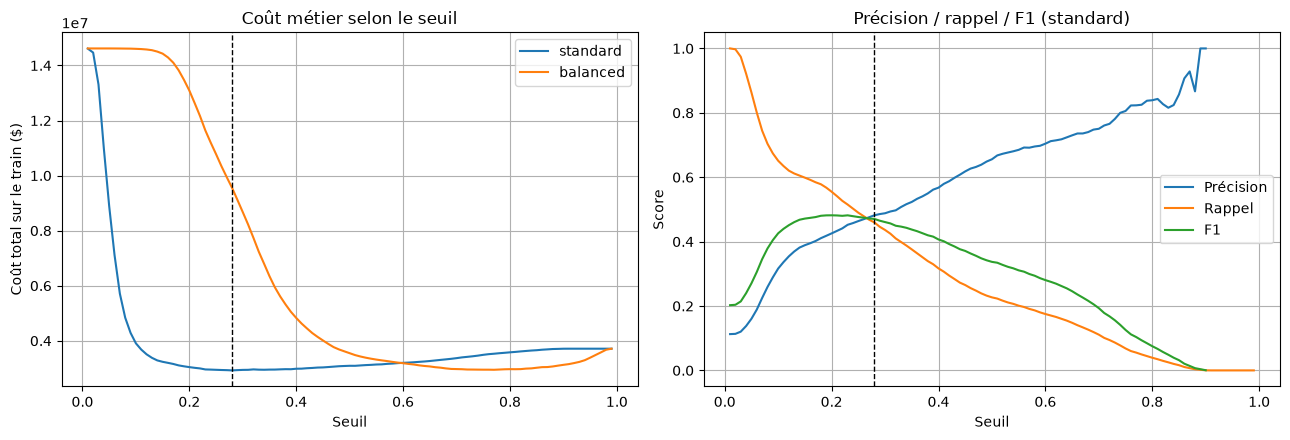

In [9]:
best_name = min(results, key=lambda k: results[k]["cout"])
best_threshold = float(results[best_name]["seuil"])
print(f"Modèle retenu : {best_name} | seuil = {best_threshold:.2f}")

p_oof = oof[best_name]
prec, rec, f1 = [], [], []
for t in grid:
    pred = p_oof >= t
    tp = int(((pred == 1) & (y_tr == 1)).sum())
    fp = int(((pred == 1) & (y_tr == 0)).sum())
    fn = int(((pred == 0) & (y_tr == 1)).sum())
    pr = tp / (tp + fp) if tp + fp else np.nan
    rc = tp / (tp + fn) if tp + fn else np.nan
    prec.append(pr)
    rec.append(rc)
    f1.append(2 * pr * rc / (pr + rc) if tp else np.nan)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, v in results.items():
    ax[0].plot(grid, v["couts"], label=name)
ax[0].axvline(best_threshold, color="k", ls="--", lw=1)
ax[0].set(xlabel="Seuil", ylabel="Coût total sur le train ($)", title="Coût métier selon le seuil")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(grid, prec, label="Précision")
ax[1].plot(grid, rec, label="Rappel")
ax[1].plot(grid, f1, label="F1")
ax[1].axvline(best_threshold, color="k", ls="--", lw=1)
ax[1].set(xlabel="Seuil", ylabel="Score", title=f"Précision / rappel / F1 ({best_name})")
ax[1].legend()
ax[1].grid(True)
plt.tight_layout()
plt.show()

AUC ROC : 0.801 | AUC PR : 0.465

Rapport de classification au seuil 0.28 :

              precision    recall  f1-score   support

         non       0.93      0.94      0.94      7310
         oui       0.51      0.47      0.49       928

    accuracy                           0.89      8238
   macro avg       0.72      0.71      0.71      8238
weighted avg       0.89      0.89      0.89      8238



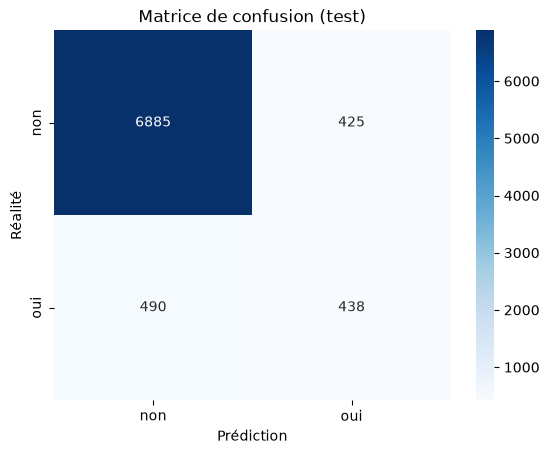

In [10]:
final = build_model(features, candidates[best_name]).fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
y_te = y_test.to_numpy()
y_pred = (p_test >= best_threshold).astype(int)

print(f"AUC ROC : {roc_auc_score(y_te, p_test):.3f} | AUC PR : {average_precision_score(y_te, p_test):.3f}")
print(f"\nRapport de classification au seuil {best_threshold:.2f} :\n")
print(classification_report(y_te, y_pred, target_names=["non", "oui"]))

cm = confusion_matrix(y_te, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["non", "oui"], yticklabels=["non", "oui"])
plt.xlabel("Prédiction")
plt.ylabel("Réalité")
plt.title("Matrice de confusion (test)")
plt.show()

In [11]:
# Comparaison du coût avec deux stratégies naïves
n_neg, n_pos = int((y_te == 0).sum()), int((y_te == 1).sum())
pd.Series({
    "Modèle (seuil choisi)": cost(y_te, p_test, best_threshold),
    "Appeler tout le monde": n_neg * COUT_FP,
    "N'appeler personne": n_pos * COUT_FN,
}, name="Coût sur le test ($)")

Modèle (seuil choisi)     702500
Appeler tout le monde    3655000
N'appeler personne        928000
Name: Coût sur le test ($), dtype: int64

In [12]:
# Sensibilité au seuil (sur le test, à titre descriptif seulement)
rows = []
for t in sorted({0.2, 0.3, 0.4, round(best_threshold, 2)}):
    pr = (p_test >= t).astype(int)
    rows.append({"Seuil": t,
                 "Rappel (oui)": recall_score(y_te, pr),
                 "Précision (oui)": precision_score(y_te, pr, zero_division=0),
                 "Accuracy": accuracy_score(y_te, pr),
                 "Coût ($)": cost(y_te, p_test, t)})
pd.DataFrame(rows).round(3)

,Seuil,Rappel (oui),Précision (oui),Accuracy,Coût ($)
0,0.20,0.595,0.452,0.873,711000
1,0.28,0.472,0.508,0.889,702500
2,0.30,0.439,0.508,0.889,718000
3,0.40,0.319,0.591,0.898,734500


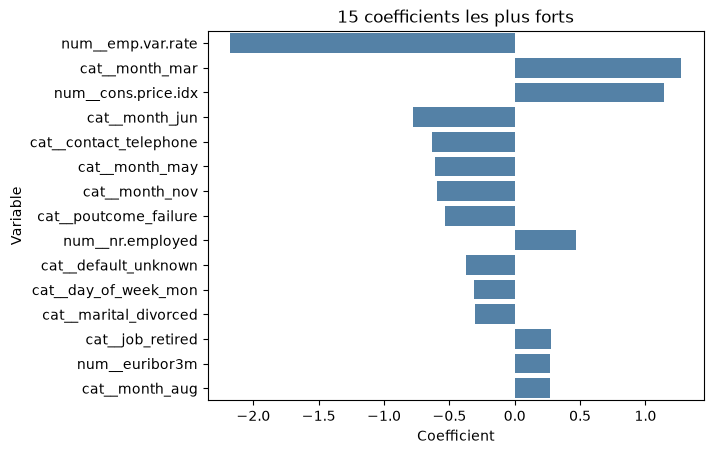

,Variable,Coefficient
4,num__emp.var.rate,-2.177
49,cat__month_mar,1.273
5,num__cons.price.idx,1.145
48,cat__month_jun,-0.780
43,cat__contact_telephone,-0.634
50,cat__month_may,-0.613
51,cat__month_nov,-0.594
59,cat__poutcome_failure,-0.530
8,num__nr.employed,0.467
34,cat__default_unknown,-0.374


In [13]:
names = final.named_steps["prep"].get_feature_names_out()
coefs = final.named_steps["clf"].coef_[0]
coef_df = (pd.DataFrame({"Variable": names, "Coefficient": coefs})
           .assign(Abs=lambda d: d["Coefficient"].abs())
           .sort_values("Abs", ascending=False).head(15))
sns.barplot(data=coef_df, y="Variable", x="Coefficient", color="steelblue")
plt.title("15 coefficients les plus forts")
plt.show()
coef_df.drop(columns="Abs").round(3)

In [14]:
deploy_model = build_model(features, candidates[best_name]).fit(X, y)
int_cols = [c for c in num_cols if pd.api.types.is_integer_dtype(X[c])]

artifact = {
    "pipeline": deploy_model,
    "threshold": best_threshold,
    "columns": list(X.columns),
    "categories": {c: sorted(X[c].unique().tolist()) for c in cat_cols},
    "defaults": {c: X[c].mode()[0] for c in cat_cols},
    "numeric_stats": {c: {"min": float(X[c].min()), "max": float(X[c].max()),
                          "median": float(X[c].median())} for c in num_cols},
    "int_cols": int_cols,
    "use_duration": USE_DURATION,
    "model_name": best_name,
}
joblib.dump(artifact, "bank_model.joblib")
print("bank_model.joblib sauvegardé |", len(artifact["columns"]), "variables d'entrée")

bank_model.joblib sauvegardé | 19 variables d'entrée


In [15]:
# Vérification : recharger et prédire sur quelques lignes brutes du test
art = joblib.load("bank_model.joblib")
sample = X_test.head(3)[art["columns"]]
print(art["pipeline"].predict_proba(sample)[:, 1].round(3))
print("Décision :", (art["pipeline"].predict_proba(sample)[:, 1] >= art["threshold"]).astype(int))

[0.066 0.453 0.578]
Décision : [0 1 1]


In [16]:
%%writefile app.py
"""Application Streamlit : prédiction de souscription à un dépôt à terme.

Lancer depuis un terminal, dans le dossier contenant ce fichier et bank_model.joblib :
    streamlit run app.py
"""
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

ARTIFACT_PATH = Path(__file__).parent / "bank_model.joblib"

LABELS = {
    "age": "Âge",
    "job": "Profession",
    "marital": "Situation maritale",
    "education": "Niveau d'éducation",
    "default": "Défaut de crédit connu",
    "housing": "Prêt immobilier",
    "loan": "Prêt personnel",
    "contact": "Type de contact",
    "month": "Mois du dernier contact",
    "day_of_week": "Jour de la semaine",
    "duration": "Durée de l'appel (secondes)",
    "campaign": "Nombre de contacts durant cette campagne",
    "pdays": "Jours depuis le dernier contact (999 = jamais contacté)",
    "previous": "Nombre de contacts avant cette campagne",
    "poutcome": "Résultat de la campagne précédente",
    "emp.var.rate": "Taux de variation de l'emploi",
    "cons.price.idx": "Indice des prix à la consommation",
    "cons.conf.idx": "Indice de confiance des consommateurs",
    "euribor3m": "Taux Euribor 3 mois",
    "nr.employed": "Nombre d'employés (milliers)",
}
PERSONAL = ["age", "job", "marital", "education", "default", "housing", "loan"]
CAMPAIGN = ["contact", "month", "day_of_week", "campaign", "pdays", "previous", "poutcome", "duration"]
MACRO = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
ORDERS = {
    "month": ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
    "day_of_week": ["mon", "tue", "wed", "thu", "fri"],
}

st.set_page_config(page_title="Prédiction bancaire", page_icon="🏦", layout="wide")
st.title("🏦 Prédiction de souscription à un dépôt à terme")


@st.cache_resource
def load_artifact():
    if not ARTIFACT_PATH.exists():
        return None
    return joblib.load(ARTIFACT_PATH)


art = load_artifact()
if art is None:
    st.error(f"Fichier introuvable : {ARTIFACT_PATH.name}")
    st.info("Exécute d'abord le notebook jusqu'à la cellule de sauvegarde, "
            "puis place bank_model.joblib dans le même dossier que app.py.")
    st.stop()

pipeline = art["pipeline"]
threshold = art["threshold"]
columns = art["columns"]
categories = art["categories"]
num_stats = art["numeric_stats"]
int_cols = set(art["int_cols"])


def sorted_options(col):
    options = categories[col]
    if col in ORDERS:
        order = ORDERS[col]
        return sorted(options, key=lambda v: order.index(v) if v in order else len(order))
    return options


def field(col, key_prefix=""):
    """Crée le widget adapté à la colonne (liste déroulante ou nombre)."""
    label = LABELS.get(col, col)
    key = f"{key_prefix}{col}"
    if col in categories:
        options = sorted_options(col)
        return st.selectbox(label, options, index=options.index(art["defaults"][col]), key=key)
    s = num_stats[col]
    if col in int_cols:
        return st.number_input(label, int(s["min"]), int(s["max"]), int(s["median"]), step=1, key=key)
    return st.number_input(label, float(s["min"]), float(s["max"]), float(s["median"]),
                           format="%.3f", key=key)


with st.form("prediction_form"):
    left, right = st.columns(2)
    values = {}
    with left:
        st.subheader("👤 Profil du client")
        for col in PERSONAL:
            if col in columns:
                values[col] = field(col)
    with right:
        st.subheader("📞 Campagne")
        for col in CAMPAIGN:
            if col in columns:
                values[col] = field(col)

    with st.expander("📈 Contexte macro-économique (valeurs médianes par défaut)"):
        st.caption("Ces indicateurs dépendent de la période. Ajuste-les si tu connais le contexte.")
        macro_cols = st.columns(len(MACRO))
        for container, col in zip(macro_cols, MACRO):
            if col in columns:
                with container:
                    values[col] = field(col)

    submitted = st.form_submit_button("🔮 Prédire", use_container_width=True)

if submitted:
    row = pd.DataFrame([values])[columns]
    proba = float(pipeline.predict_proba(row)[0, 1])
    will_subscribe = proba >= threshold

    st.markdown("---")
    st.subheader("📊 Résultat")
    c1, c2, c3 = st.columns(3)
    c1.metric("Probabilité de souscription", f"{proba * 100:.1f} %")
    c2.metric("Seuil de décision", f"{threshold * 100:.1f} %")
    c3.metric("Décision", "Contacter" if will_subscribe else "Ne pas prioriser")
    st.progress(min(max(proba, 0.0), 1.0))

    if will_subscribe:
        st.success("✅ Probabilité au-dessus du seuil : ce client vaut la peine d'être contacté.")
    else:
        st.info("📉 Probabilité sous le seuil : ce client n'est pas prioritaire.")

    if art.get("use_duration"):
        st.warning("Le modèle utilise la durée de l'appel, qui n'est connue qu'après l'appel : "
                   "cette prédiction n'est pas utilisable avant de contacter le client.")

st.markdown("---")
st.caption("Le seuil de décision a été choisi pour minimiser un coût métier "


Writing app.py
